alpha=0.1: MSE=20921943.3287
alpha=0.5: MSE=20919314.7017
alpha=0.6: MSE=20918662.9767
alpha=10: MSE=20877929.4770
alpha=30: MSE=20872155.1869
alpha=50: MSE=20968477.3964
alpha=68: MSE=21142177.6854
alpha=100: MSE=21634805.9942


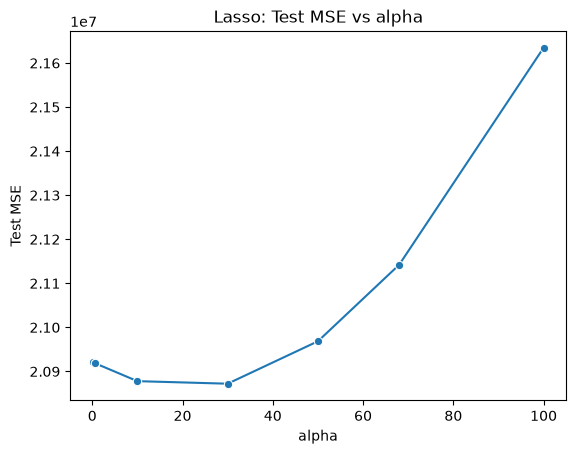

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("insurance.csv")
X = df.drop(columns=["charges"])
Y = df["charges"]

X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"male": 1, "female": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

X["age_smoker"] = X["age"] * X["smoker"]
X["bmi_smoker"] = X["bmi"] * X["smoker"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Scale features (fit on train only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

alphas = [0.1, 0.5, 0.6, 10, 30, 50, 68, 100]
mses = []

for a in alphas:
    model = Lasso(alpha=a, max_iter=10000)
    model.fit(X_train_s, Y_train)
    Y_pred = model.predict(X_test_s)
    mse = mean_squared_error(Y_test, Y_pred)
    print(f"alpha={a}: MSE={mse:.4f}")
    mses.append(mse)

sns.lineplot(x=alphas, y=mses, marker="o")
plt.xlabel("alpha")
plt.ylabel("Test MSE")
plt.title("Lasso: Test MSE vs alpha")
plt.show()

In [3]:
from sklearn.linear_model import LassoCV

In [8]:
al = [0.01, 0.5, 0.6, 10, 30, 50, 68, 100]
lasso_cv = LassoCV(
    alphas=al,
    cv=5,
    max_iter=1000,
    copy_X= True,
    random_state=42
)
lasso_cv.fit(X_train, Y_train)
print("the best alpha:",lasso_cv.alpha_)

y_pred =lasso_cv.predict(X_test)
mse = mean_squared_error(Y_test,y_pred)
print("mse:- ", mse)

# r2score
from sklearn.metrics import r2_score
r2= r2_score(Y_test, y_pred)
print("r2:-", r2)

the best alpha: 0.01
mse:-  20922527.326629896
r2:- 0.8652322171937452


## ElasticNet Overview

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.datasets import make_regression


## logistic Regression 
for classification